# Figure 1 — snow modeling sites near Juneau

Cassie Lumbrazo · Updated October 2026 · Environment: **rasterio**

Run top to bottom to compare the original HRRR elevation contours with contours from the merged **20 m ArcticDEM mosaic**. Both maps retain the first figure's styling, HRRR temperature and hillshade, site labels, map extent, and Alaska inset.

Outputs are PNG (300 dpi) and PDF in `snow_modeling_point/figures/`: `figure1` for the original and `figure1_dem20m` for the DEM version.

## Setup

Set the illustrative HRRR timestamp and shared map settings below. Temperature uses the nearest stored timestamp; both terrain sources are expected in WGS 84 / UTM Zone 8N (EPSG:32608).

In [1]:
%matplotlib inline
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import rioxarray  # Register the xarray CRS accessor.
import rasterio
from rasterio.windows import Window, from_bounds
from pyproj import CRS
import geopandas as gpd
from shapely.geometry import Point, box
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.colors import LightSource, TwoSlopeNorm
from matplotlib_scalebar.scalebar import ScaleBar
import seaborn as sns
import cartopy.crs as ccrs
import cartopy.feature as cfeature

sns.set_theme()

In [2]:
HRRR_PATH = Path('/hdd/snow_hydrology/hrrrak/large_juneau_domain/netcdf/hrrrak_merged_grib_f567_WY2025_utm.nc')
DEM_PATH = Path('/hdd/snow_hydrology/DEMs/ArcticDEM_edits/icefield_domain/jif_mosaic/jif_tiles_utm8n_20m.tif')
alaska_shp = '/hdd/snow_hydrology/shape_files/alaska_censusdotgov.shp'
OUTPUT_DIR = Path('/home/cassie/python/repos/snow_modeling_point/figures')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

plot_time = pd.Timestamp('2025-02-20T18:00:00')
show_temperature = True
fontsize = 9
site_marker_size = 85
contour_levels = [250, 500, 750, 1000, 1250, 1500]
temp_norm = TwoSlopeNorm(vmin=-5, vcenter=0, vmax=5)
proj = ccrs.UTM(8)
pc = ccrs.PlateCarree()

# Load only the orography and selected temperature snapshot, then close the file.
with xr.open_dataset(HRRR_PATH) as ds:
    hrrr_crs = ds.rio.crs
    if hrrr_crs is None:
        # Existing convention: this HRRR file was reprojected to EPSG:32608.
        hrrr_crs = CRS.from_epsg(32608)
        print('HRRR CRS absent; assuming EPSG:32608 as in the original figure.')
    if CRS(hrrr_crs) != CRS.from_epsg(32608):
        raise ValueError(f'Unexpected HRRR CRS: {hrrr_crs}')
    terrain = ds['orog'].isel(time=0).load()
    temp = ds['temp'].sel(time=plot_time, method='nearest').load() - 273.15

x, y, z = terrain.x.values, terrain.y.values, terrain.values
actual_time = pd.Timestamp(temp.time.values)
xmin, xmax = np.nanmin(x), np.nanmax(x)
ymin, ymax = np.nanmin(y), np.nanmax(y)
print(f'HRRR CRS: {hrrr_crs}; selected time: {actual_time} UTC')

HRRR CRS absent; assuming EPSG:32608 as in the original figure.
HRRR CRS: EPSG:32608; selected time: 2025-02-20 18:00:00 UTC


## Shared map layout

The plotting function keeps both versions consistent; its elevation-grid arguments control the contour source.

In [3]:
def plot_figure1(contour_x, contour_y, contour_z, output_stem):
    """Draw the shared map layout with contours from the supplied elevation grid.

    Temperature and hillshade retain the HRRR resolution; only contours vary.
    Both versions use the first map's extent, red outlines, and larger inset.
    """
    sites = {
        "PPSA": {"lat": 58.26200, "lon": -134.51700, "elev": 670},
        "TRAM": {"lat": 58.29710, "lon": -134.38600, "elev": 529},
        "HEEN": {"lat": 58.69652, "lon": -134.86448, "elev": 548},
    }

    gdf_sites = gpd.GeoDataFrame(
        {
            "site_id": list(sites.keys()),
            "elev_m": [sites[s]["elev"] for s in sites],
            "geometry": [Point(sites[s]["lon"], sites[s]["lat"]) for s in sites],
        },
        crs="EPSG:4326",
    )

    ls = LightSource(azdeg=315, altdeg=45)
    hillshade = ls.hillshade(
        z,
        vert_exag=1.5,
        dx=np.nanmedian(np.diff(x)),
        dy=np.nanmedian(np.diff(y)),
    )

    xmin, xmax = np.nanmin(x), np.nanmax(x)
    ymin, ymax = np.nanmin(y), np.nanmax(y)

    domain_poly_utm = gpd.GeoDataFrame(
        geometry=[box(xmin, ymin, xmax, ymax)],
        crs="EPSG:32608",
    ).to_crs("EPSG:4326")

    fig = plt.figure(figsize=(7.2, 6.2), dpi=300)

    ax = fig.add_axes([0.08, 0.10, 0.72, 0.82], projection=proj)

    ax_inset = fig.add_axes(
        [0.46, 0.62, 0.30, 0.30],
        projection=ccrs.AlbersEqualArea(
            central_longitude=-154,
            central_latitude=50,
            standard_parallels=(55, 65),
        )
    )

    cax = fig.add_axes([0.75, 0.20, 0.025, 0.60])

    ax.pcolormesh(
        x, y, hillshade,
        cmap="Greys",
        shading="auto",
        transform=proj,
        alpha=0.95,
        zorder=1,
    )

    if show_temperature:
        im = ax.pcolormesh(
            x, y, temp.values,
            cmap="coolwarm",
            shading="auto",
            norm=temp_norm,
            transform=proj,
            alpha=0.62,
            zorder=2,
        )

        cbar = fig.colorbar(im, cax=cax)
        cbar.set_label("HRRR-AK air temperature (°C)", fontsize=fontsize)
        cbar.ax.tick_params(labelsize=fontsize - 1)
    else:
        cax.set_visible(False)

    contours = ax.contour(
        contour_x, contour_y, contour_z,
        levels=contour_levels,
        colors="black",
        linewidths=0.45,
        alpha=0.55,
        transform=proj,
        zorder=3,
    )

    ax.clabel(
        contours,
        inline=True,
        fontsize=7,
        fmt="%d m",
    )

    ax.set_extent([xmin, xmax, ymin, ymax], crs=proj)

    ax.add_feature(cfeature.COASTLINE, linewidth=0.8, zorder=4)
    ax.add_feature(cfeature.LAKES, linewidth=0.4, alpha=0.4, zorder=4)
    ax.add_feature(cfeature.RIVERS, linewidth=0.3, alpha=0.35, zorder=4)

    gl = ax.gridlines(
        draw_labels=True,
        linewidth=0.35,
        color="gray",
        alpha=0.45,
        linestyle="--",
    )

    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {"size": 8}
    gl.ylabel_style = {"size": 8}

    label_offsets = {
        "PPSA": (-0.035, -0.035),
        "TRAM": (0.040, 0.030),
        "HEEN": (0.035, 0.035),
    }

    for _, row in gdf_sites.iterrows():
        lon = row.geometry.x
        lat = row.geometry.y
        site = row["site_id"]

        ax.scatter(
            lon, lat,
            s=site_marker_size,
            marker="o",
            facecolor="red",
            edgecolor="black",
            linewidth=1.0,
            transform=pc,
            zorder=10,
        )

        dx, dy = label_offsets.get(site, (0.02, 0.02))

        txt = ax.text(
            lon + dx,
            lat + dy,
            f"{site}\n{int(row['elev_m'])} m",
            fontsize=8.5,
            fontweight="bold",
            ha="center",
            va="center",
            color="white",
            transform=pc,
            zorder=11,
        )

        txt.set_path_effects([
            pe.withStroke(linewidth=2.3, foreground="black")
        ])

    landmarks = [
        {
            "name": "JNU Airport",
            "lon": -134.576,
            "lat": 58.354,
            "marker": "s",
            "dx": -0.055,
            "dy": 0.02,
            "ha": "left",
        },
        {
            "name": "Douglas Island",
            "lon": -134.575,
            "lat": 58.275,
            "marker": "s",
            "dx": 0.06,
            "dy": 0.02,
            "ha": "right",
        },
    ]

    for lm in landmarks:
        ax.scatter(
            lm["lon"], lm["lat"],
            transform=pc,
            s=35,
            marker=lm["marker"],
            facecolor="black",
            edgecolor="white",
            linewidth=0.5,
            zorder=9,
        )

        txt = ax.text(
            lm["lon"] + lm["dx"],
            lm["lat"] + lm["dy"],
            lm["name"],
            fontsize=7,
            color="white",
            ha=lm["ha"],
            va="center",
            transform=pc,
            zorder=10,
        )

        txt.set_path_effects([
            pe.withStroke(linewidth=2.0, foreground="black")
        ])

    scalebar = ScaleBar(
        dx=1,
        units="m",
        location="lower left",
        length_fraction=0.22,
        box_alpha=0.85,
        font_properties={"size": 8},
    )

    ax.add_artist(scalebar)

    ax.annotate(
        "N",
        xy=(0.03, 0.185),
        xytext=(0.03, 0.105),
        xycoords=ax.transAxes,
        ha="center",
        va="center",
        fontsize=11,
        fontweight="bold",
        arrowprops=dict(
            facecolor="black",
            edgecolor="black",
            width=2,
            headwidth=7,
            headlength=8,
        ),
        zorder=20,
    )

    if show_temperature:
        timestamp_str = actual_time.strftime("%Y-%m-%d %H:%M UTC")

        ax.text(
            0.98, 0.98,
            timestamp_str,
            transform=ax.transAxes,
            ha="right",
            va="top",
            fontsize=8.5,
            fontweight="bold",
            bbox=dict(
                facecolor="white",
                edgecolor="black",
                alpha=0.88,
                boxstyle="round,pad=0.25",
            ),
            zorder=20,
        )

    ak = gpd.read_file(alaska_shp).to_crs(ax_inset.projection.proj4_init)

    ak.plot(
        ax=ax_inset,
        facecolor="0.92",
        edgecolor="black",
        linewidth=0.45,
        zorder=1,
    )

    domain_poly_ak = domain_poly_utm.to_crs(ax_inset.projection.proj4_init)
    domain_poly_ak.boundary.plot(
        ax=ax_inset,
        edgecolor="red",
        linewidth=1.4,
        zorder=5,
    )

    ax_inset.set_extent([-180, -128, 50, 73], crs=pc)
    ax_inset.set_axis_off()

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_edgecolor("red")
        spine.set_linewidth(2.5)

    ax.set_title(
        "Snow Modeling Sites near Juneau, Alaska",
        fontsize=11,
        fontweight="bold",
        pad=8,
    )


    fig.savefig(OUTPUT_DIR / f'{output_stem}.png', dpi=300, bbox_inches='tight')
    fig.savefig(OUTPUT_DIR / f'{output_stem}.pdf', bbox_inches='tight')
    plt.show()
    plt.close(fig)

## Original — HRRR orography

Preserves the original map with 250 m elevation contours from HRRR orography. Exports `figure1.png` and `figure1.pdf`.

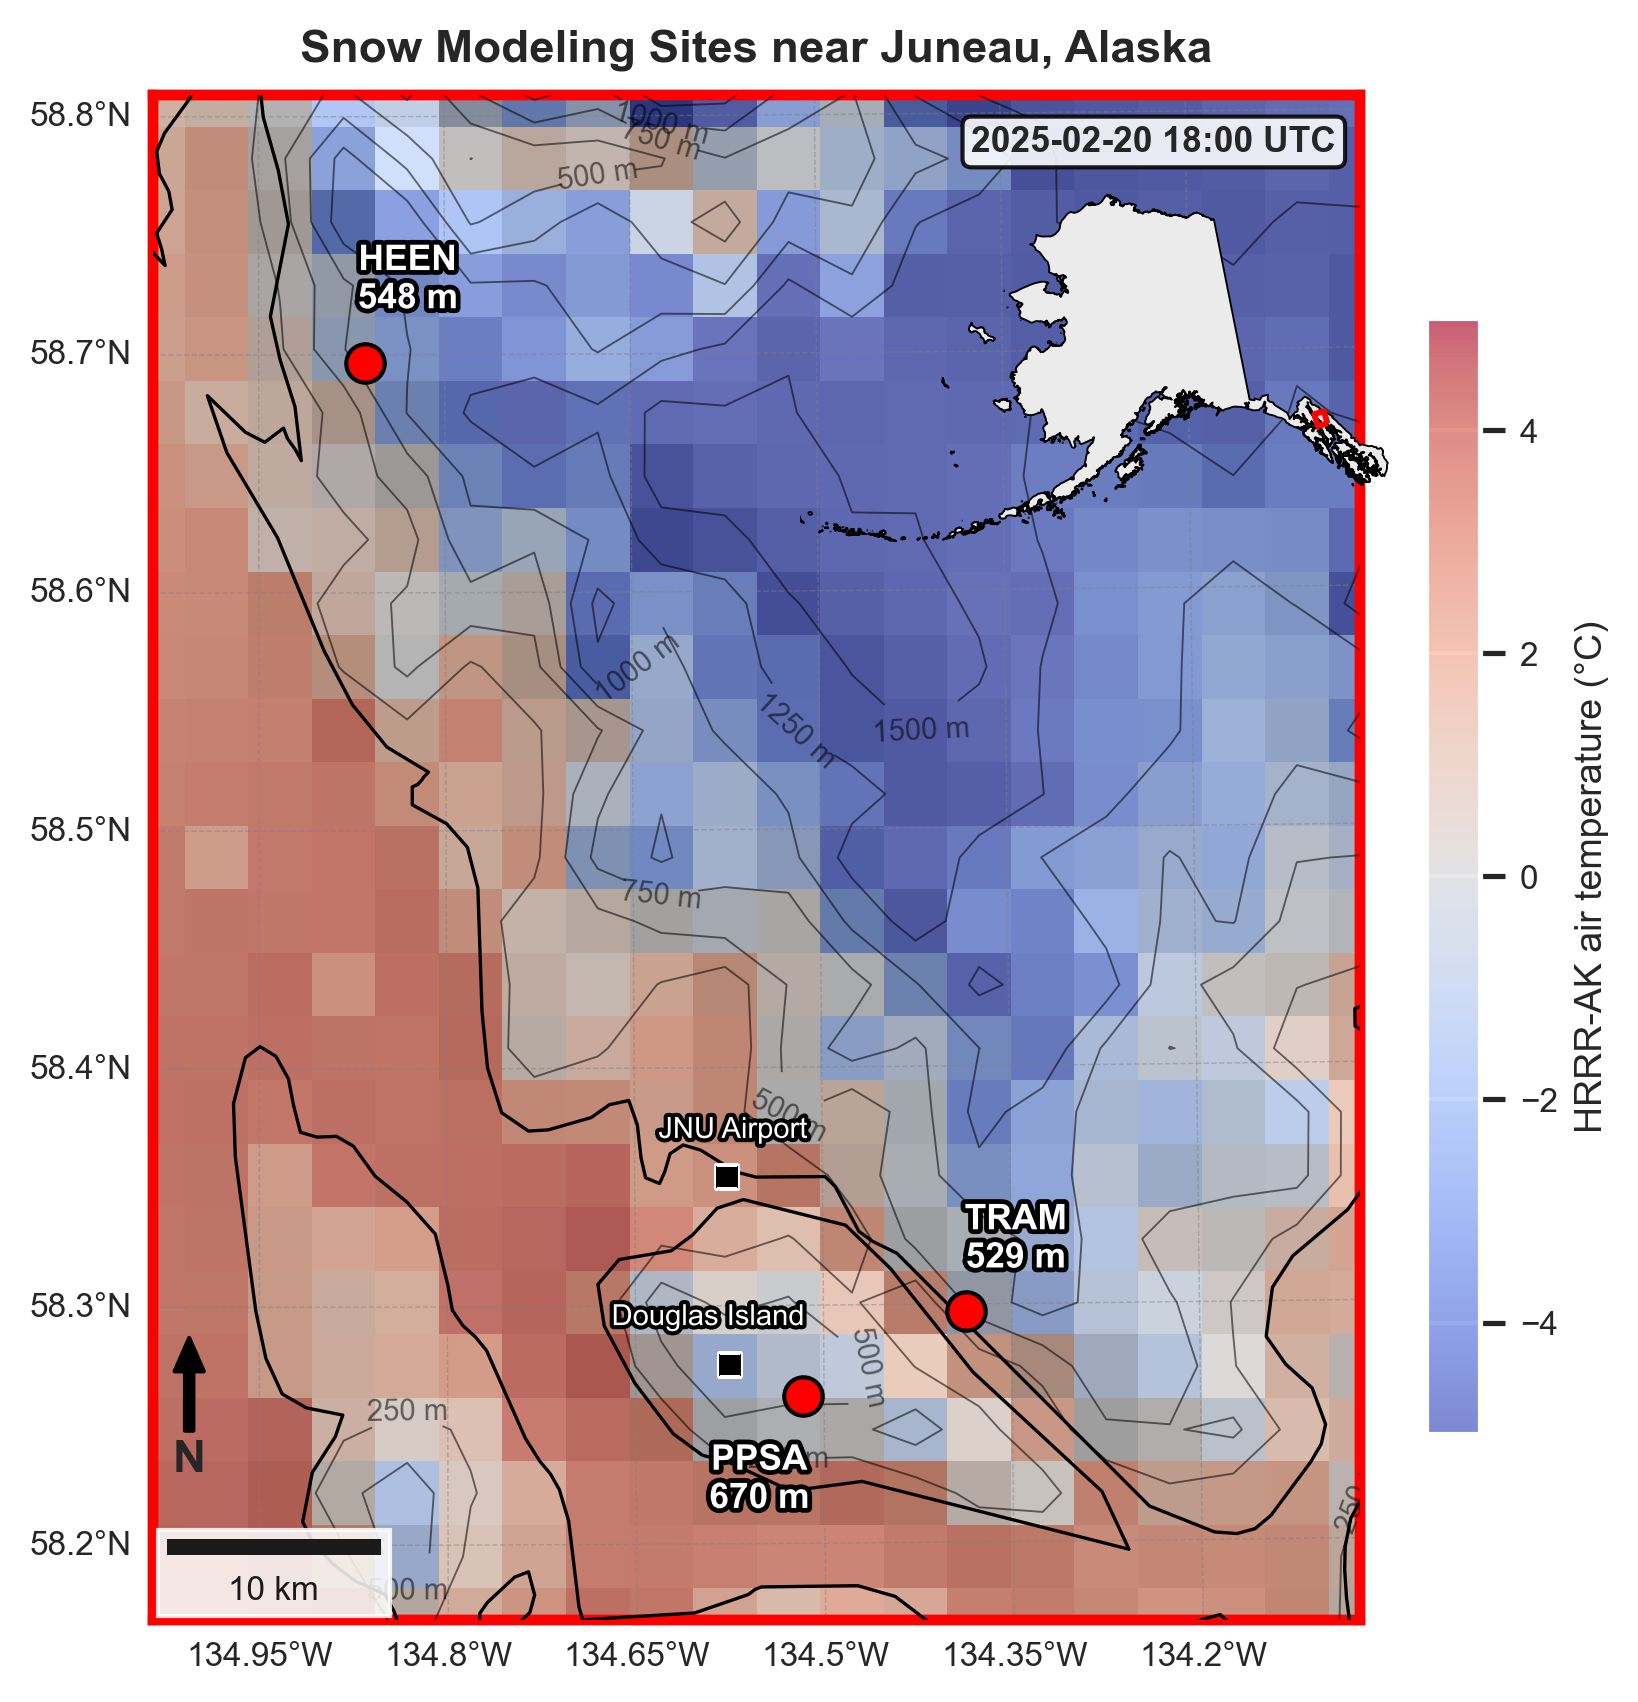

In [4]:
plot_figure1(x, y, z, output_stem='figure1')

## New version — merged 20 m DEM

Read only the map window at native **20 m** spacing. The file CRS and resolution are checked and nodata are masked; no smoothing or resampling is applied. Contours stop where DEM data are missing. Contour levels remain 250–1500 m at 250 m intervals for comparison with the original.

Only the contour source changes; temperature and hillshade remain on the HRRR grid. Exports `figure1_dem20m.png` and `figure1_dem20m.pdf`. The older intermediate 2 m DEM resampling workflow is no longer needed.

Contour source: jif_tiles_utm8n_20m.tif; EPSG:32608; (20.0, 20.0) m
Map window: (3569, 2727); valid pixels: 9,728,527/9,732,663


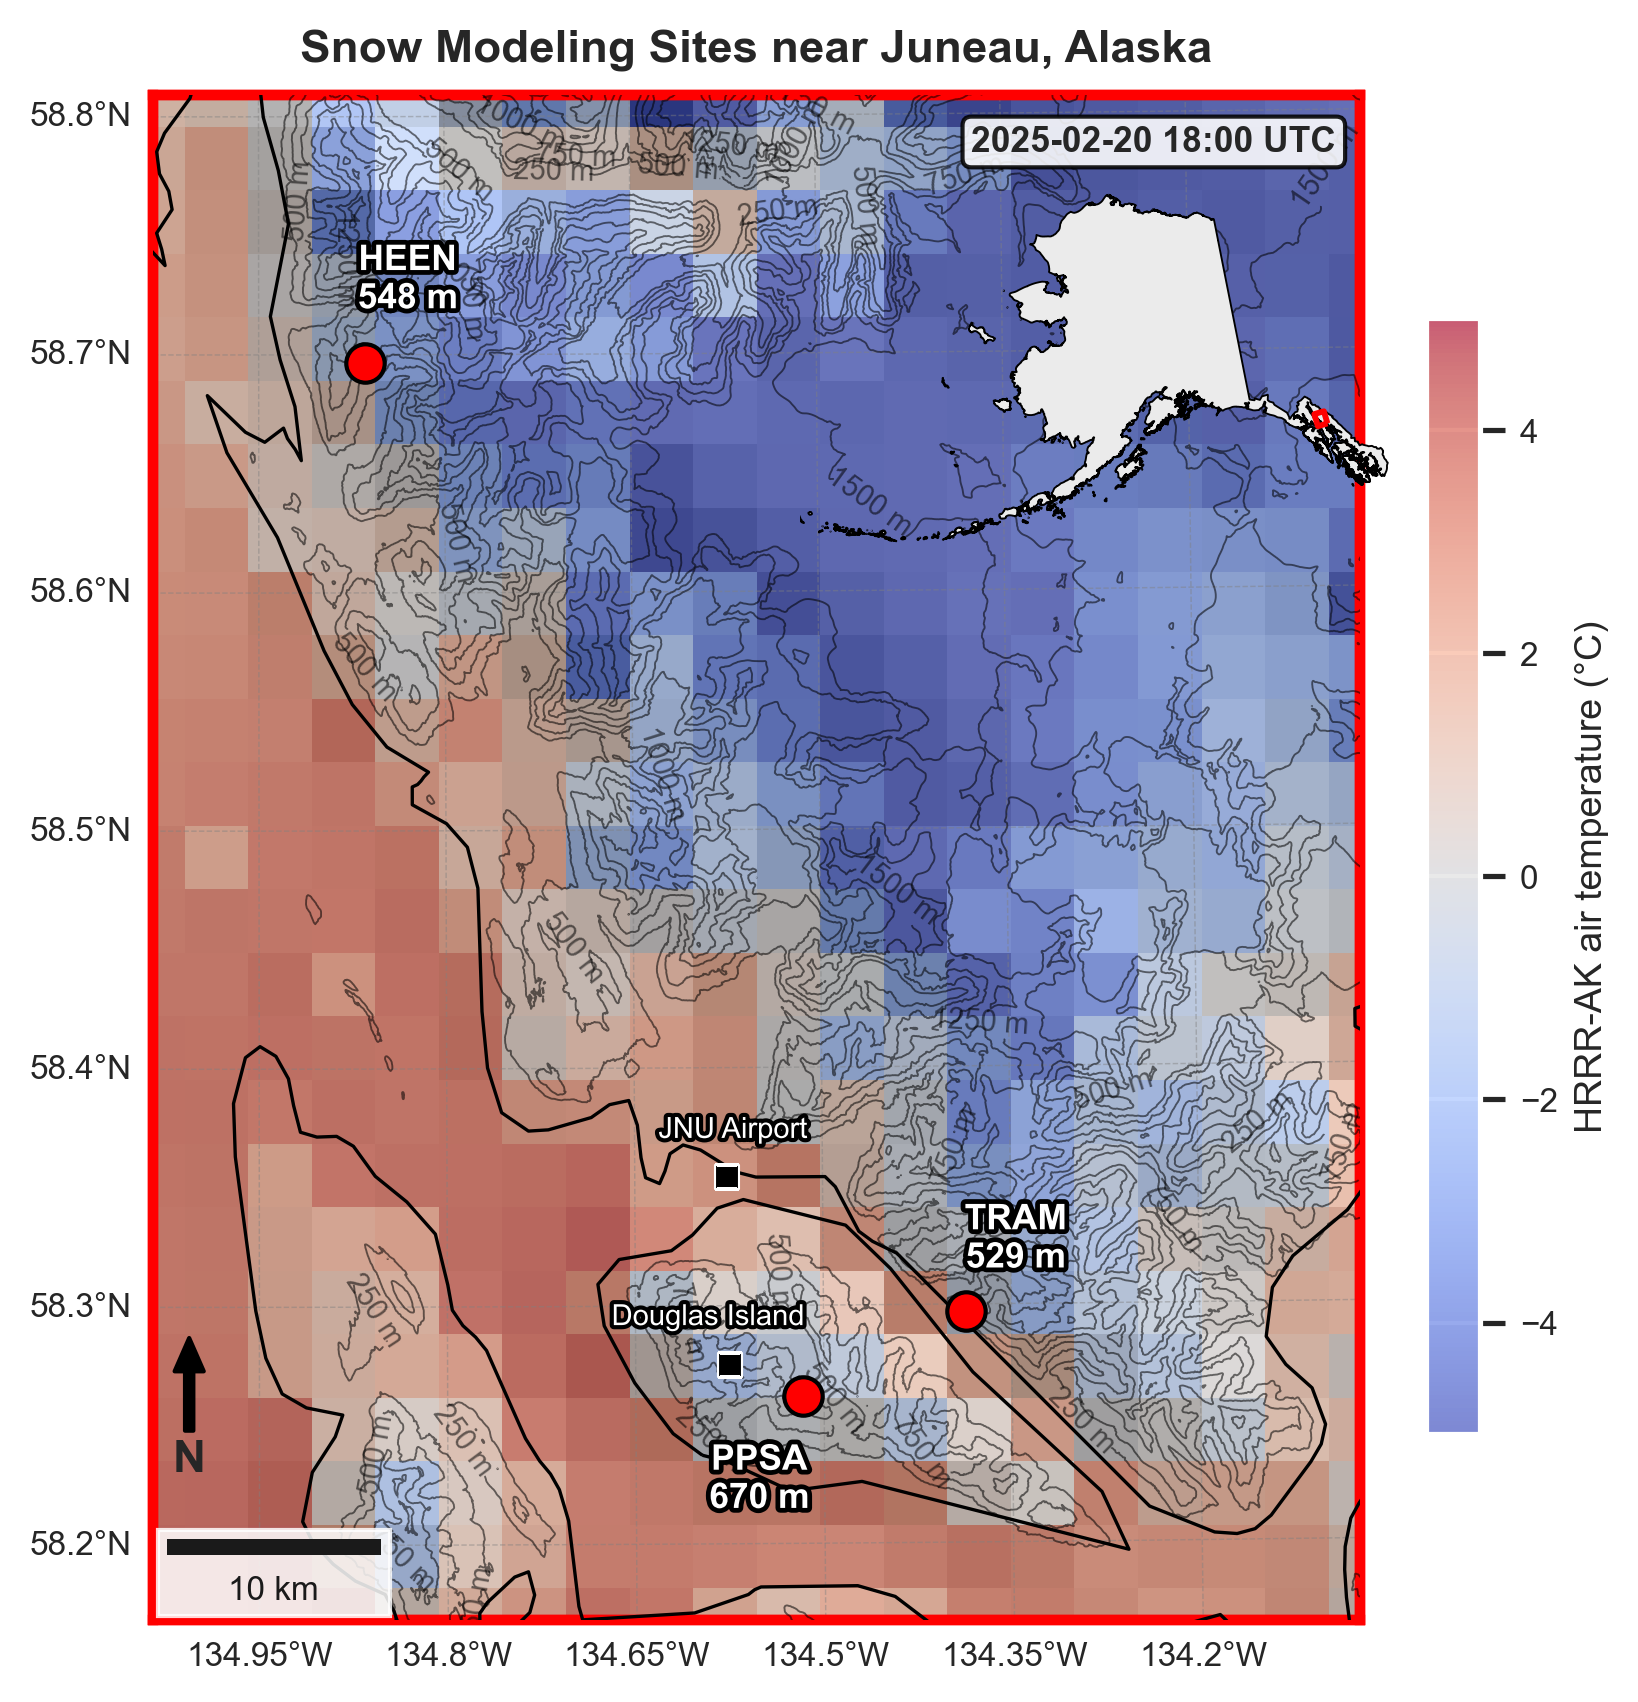

In [5]:
with rasterio.open(DEM_PATH) as src:
    if CRS(src.crs) != CRS.from_epsg(32608):
        raise ValueError(f'Expected WGS 84 / UTM 8N, found {src.crs}')
    if not np.allclose(src.res, (20, 20)):
        raise ValueError(f'Expected a 20 m mosaic, found {src.res}')
    # Pad by one pixel for contours crossing the fixed map boundary.
    requested = from_bounds(xmin - 20, ymin - 20, xmax + 20, ymax + 20, src.transform)
    c0, r0 = int(np.floor(requested.col_off)), int(np.floor(requested.row_off))
    c1, r1 = int(np.ceil(requested.col_off + requested.width)), int(np.ceil(requested.row_off + requested.height))
    window = Window(c0, r0, c1 - c0, r1 - r0).intersection(Window(0, 0, src.width, src.height))
    dem_z = src.read(1, window=window, masked=True).astype('float32')
    transform = src.window_transform(window)
    dem_x = transform.c + (np.arange(dem_z.shape[1]) + 0.5) * transform.a
    dem_y = transform.f + (np.arange(dem_z.shape[0]) + 0.5) * transform.e
    print(f'Contour source: {DEM_PATH.name}; {src.crs}; {src.res} m')
    print(f'Map window: {dem_z.shape}; valid pixels: {dem_z.count():,}/{dem_z.size:,}')
if dem_z.count() == 0:
    raise ValueError('No valid DEM elevations in the map window.')

plot_figure1(dem_x, dem_y, dem_z, output_stem='figure1_dem20m')